# **CS 5361/6361 Machine Learning**

**Decision Trees - quiz solution, combining trees, overfitting**

The code below show the application of regression trees to the California Housing datset.

You can see the documentation at:
https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html

In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.datasets import fetch_california_housing
import numpy as np
import matplotlib.pyplot as plt

dataset = fetch_california_housing()
x = dataset.data
y = dataset.target
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.20, random_state=5361)

model = DecisionTreeRegressor()
model.fit(X_train, y_train)
print(f'Model size: depth = {model.get_depth()} number of leaves = {model.get_n_leaves()}')
pred = model.predict(X_test)

print(f'mean_squared_error: {mean_squared_error(y_test,pred):8.6f}')

Model size: depth = 35 number of leaves = 15882
mean_squared_error: 0.538699


# Part 1

Write code to find the setting of the max_depth parameter that results in the smallest mean squared error.

In [ ]:
min_err = np.inf
best_depth = -1
for max_depth in range(1,40):
  model = DecisionTreeRegressor(max_depth = max_depth)
  model.fit(X_train, y_train)
  print(f'Model size: depth = {model.get_depth()} number of leaves = {model.get_n_leaves()}')
  pred = model.predict(X_test)
  mse = mean_squared_error(y_test,pred)
  print(f'mean_squared_error: {mse:8.6f}')
  if mse < min_err:
    min_err = mse
    best_depth = max_depth

print(f'Best max_depth value {best_depth}, mean_squared_error: {min_err:8.6f}')


Model size: depth = 1 number of leaves = 2
mean_squared_error: 0.928355
Model size: depth = 2 number of leaves = 4
mean_squared_error: 0.741945
Model size: depth = 3 number of leaves = 8
mean_squared_error: 0.633110
Model size: depth = 4 number of leaves = 16
mean_squared_error: 0.578763
Model size: depth = 5 number of leaves = 32
mean_squared_error: 0.526278
Model size: depth = 6 number of leaves = 64
mean_squared_error: 0.486841
Model size: depth = 7 number of leaves = 126
mean_squared_error: 0.455770
Model size: depth = 8 number of leaves = 245
mean_squared_error: 0.424935
Model size: depth = 9 number of leaves = 452
mean_squared_error: 0.423470
Model size: depth = 10 number of leaves = 796
mean_squared_error: 0.426065
Model size: depth = 11 number of leaves = 1322
mean_squared_error: 0.432876
Model size: depth = 12 number of leaves = 2044
mean_squared_error: 0.453211
Model size: depth = 13 number of leaves = 2968
mean_squared_error: 0.469030
Model size: depth = 14 number of leaves 

Let's plot the training and testing errors for all depths from 1 to 36.

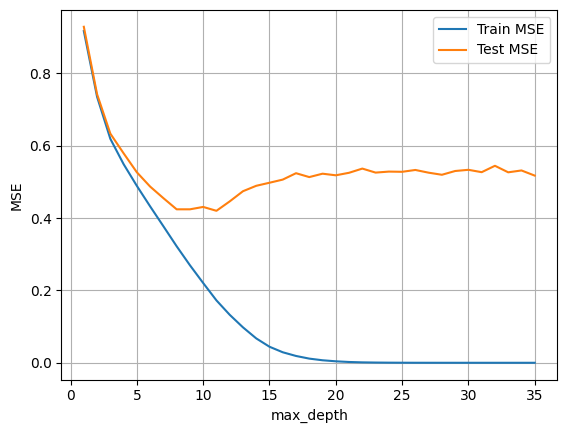

In [ ]:
err_trn = []
err_tst = []
depths = np.arange(1,36)

for max_depth in depths:
  model = DecisionTreeRegressor(max_depth = max_depth)
  model.fit(X_train, y_train)
  #print(f'Model size: depth = {model.get_depth()} number of leaves = {model.get_n_leaves()}')
  pred = model.predict(X_train)
  mse = mean_squared_error(y_train,pred)
  err_trn.append(mse)
  pred = model.predict(X_test)
  mse = mean_squared_error(y_test,pred)
  err_tst.append(mse)

plt.figure()
plt.plot(depths,err_trn,label='Train MSE')
plt.plot(depths,err_tst,label='Test MSE')
plt.xlabel('max_depth')
plt.ylabel('MSE')
plt.legend()
plt.grid(True)
plt.show()

As we can see, the training error decreases until it reaches 0 as we increase the maximum depth. However, the test error decreases with maximum depth until it reaches a minimum, then it starts increasing. When this happens, we say the the model is **overfitting** the training data.

# Part 2

Write code to evaluate the performance of the model when a random splitter is used, instead of the best splitter; use the default maximum depth. Since the performace varies from run to run using random splitting, compute the average mse accross 30 runs and compare that average with that of the 'best' split.

In [ ]:
sum_err = 0
n_tests = 30
model = DecisionTreeRegressor(max_depth= 14, splitter='random')

for i in range(n_tests):
  model.fit(X_train, y_train)
  print(f'Model size: depth = {model.get_depth()} number of leaves = {model.get_n_leaves()}')
  pred = model.predict(X_test)
  mse = mean_squared_error(y_test,pred)
  print(f'mean_squared_error: {mse:8.6f}')
  sum_err += mse

print(f'Average mean_squared_error: {sum_err/n_tests:8.6f}')

Model size: depth = 14 number of leaves = 3237
mean_squared_error: 0.478125
Model size: depth = 14 number of leaves = 2259
mean_squared_error: 0.496947
Model size: depth = 14 number of leaves = 2004
mean_squared_error: 0.502854
Model size: depth = 14 number of leaves = 3059
mean_squared_error: 0.538466
Model size: depth = 14 number of leaves = 1380
mean_squared_error: 0.540992
Model size: depth = 14 number of leaves = 2160
mean_squared_error: 0.451643
Model size: depth = 14 number of leaves = 2864
mean_squared_error: 0.469137
Model size: depth = 14 number of leaves = 2853
mean_squared_error: 0.495312
Model size: depth = 14 number of leaves = 2298
mean_squared_error: 0.525672
Model size: depth = 14 number of leaves = 2092
mean_squared_error: 0.468580
Model size: depth = 14 number of leaves = 2300
mean_squared_error: 0.533608
Model size: depth = 14 number of leaves = 2912
mean_squared_error: 0.488368
Model size: depth = 14 number of leaves = 3121
mean_squared_error: 0.471517
Model size: 

# Part 3

Modify your code above to, instead of averaging the mse of the models, you average their predictions. Then compute the mse for that average prediction.

In [ ]:
n_tests = 30
model = DecisionTreeRegressor(splitter='random')
pred_array = np.zeros((X_test.shape[0],n_tests))

for i in range(n_tests):
  model.fit(X_train, y_train)
  print(f'Model {i:2}, depth = {model.get_depth()} number of leaves = {model.get_n_leaves()}')
  pred = model.predict(X_test)
  mse = mean_squared_error(y_test,pred)
  print(f'mean_squared_error: {mse:8.6f}')
  pred_array[:,i] = pred

pred = np.mean(pred_array,axis=1)
print(f'Mean_squared_error using prediction averages: {mean_squared_error(y_test,pred):8.6f}')

Model  0, depth = 40 number of leaves = 16059
mean_squared_error: 0.555869
Model  1, depth = 47 number of leaves = 16063
mean_squared_error: 0.590717
Model  2, depth = 41 number of leaves = 16064
mean_squared_error: 0.533245
Model  3, depth = 38 number of leaves = 16063
mean_squared_error: 0.645571
Model  4, depth = 43 number of leaves = 16055
mean_squared_error: 0.591019
Model  5, depth = 40 number of leaves = 16067
mean_squared_error: 0.611972
Model  6, depth = 41 number of leaves = 16059
mean_squared_error: 0.531924
Model  7, depth = 42 number of leaves = 16042
mean_squared_error: 0.566315
Model  8, depth = 35 number of leaves = 16077
mean_squared_error: 0.603872
Model  9, depth = 35 number of leaves = 16068
mean_squared_error: 0.520657
Model 10, depth = 37 number of leaves = 16075
mean_squared_error: 0.590817
Model 11, depth = 38 number of leaves = 16085
mean_squared_error: 0.615338
Model 12, depth = 39 number of leaves = 16092
mean_squared_error: 0.607905
Model 13, depth = 40 numb

Why does the error decrease if we average the predictions of the individual trees?

Suppose that for a give test example, a tree predicts a value that is too high and another predicts a value that is too low, what will happen if we average these two predictions?

The plot below shows the predictions made by each of the trees for some selected test examples (blue dots), the average of the predictions (red stars), and the correct y values (green stars).

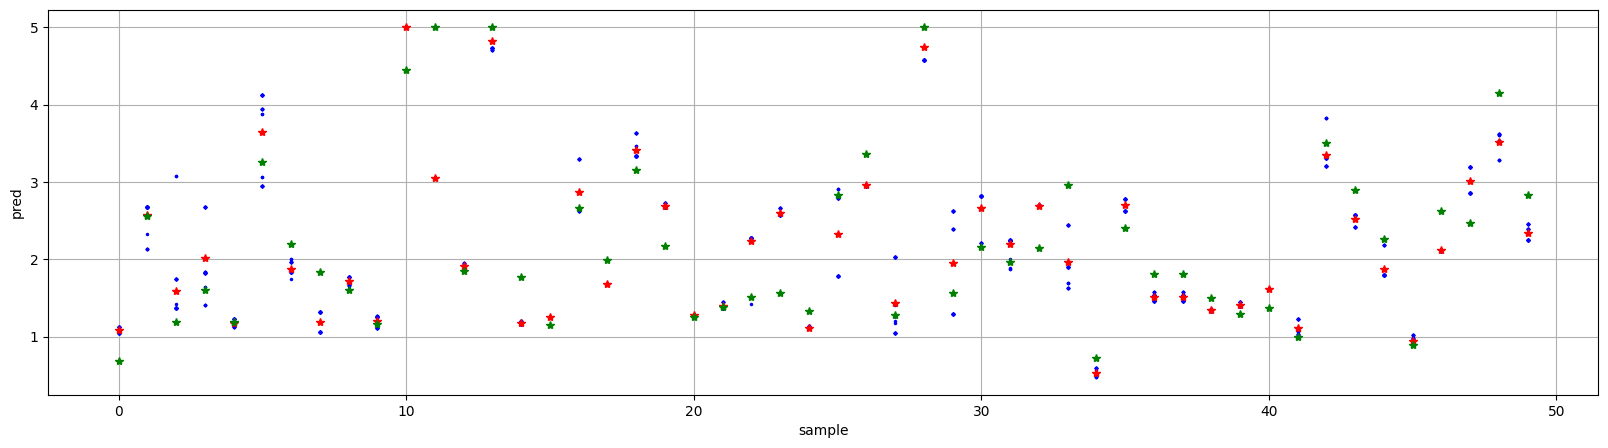

In [ ]:
np.random.seed(0)
samples = np.random.randint(0,y_test.shape[0],size=50)
plt.figure(figsize=(20,5))
for i,s in enumerate(samples):
  plt.plot([i]*n_tests,pred_array[s],'.b',ms=3)
  plt.plot(i,pred[s],'*r')
  plt.plot(i,y_test[s],'*g')
plt.xlabel('sample')
plt.ylabel('pred')
plt.grid(True)
plt.show()

In [ ]:
n_tests = 30
model = DecisionTreeRegressor(splitter='random')
pred_array = np.zeros((X_test.shape[0],n_tests))

for i in range(n_tests):
  model.fit(X_train, y_train)
  print(f'Model {i:2}, depth = {model.get_depth()} number of leaves = {model.get_n_leaves()}')
  pred = model.predict(X_test)
  mse = mean_squared_error(y_test,pred)
  print(f'mean_squared_error: {mse:8.6f}')
  pred_array[:,i] = pred
  pred = np.mean(pred_array[:,:i+1],axis=1)
  print(f'Mean_squared_error using prediction averages: {mean_squared_error(y_test,pred):8.6f}')

Model  0, depth = 10 number of leaves = 423
mean_squared_error: 0.552511
Mean_squared_error using prediction averages: 0.552511
Model  1, depth = 10 number of leaves = 266
mean_squared_error: 0.546330
Mean_squared_error using prediction averages: 0.489221
Model  2, depth = 10 number of leaves = 559
mean_squared_error: 0.467080
Mean_squared_error using prediction averages: 0.435877
Model  3, depth = 10 number of leaves = 280
mean_squared_error: 0.595183
Mean_squared_error using prediction averages: 0.444947
Model  4, depth = 10 number of leaves = 540
mean_squared_error: 0.567473
Mean_squared_error using prediction averages: 0.448600
Model  5, depth = 10 number of leaves = 542
mean_squared_error: 0.461771
Mean_squared_error using prediction averages: 0.420302
Model  6, depth = 10 number of leaves = 293
mean_squared_error: 0.583157
Mean_squared_error using prediction averages: 0.428352
Model  7, depth = 10 number of leaves = 383
mean_squared_error: 0.500070
Mean_squared_error using predic

We can plot the mse for different numbers of trees. We can see that there is no overfitting as we add more trees to the group.

Mean_squared_error using prediction average of 1 models: 0.535153
Mean_squared_error using prediction average of 2 models: 0.394732
Mean_squared_error using prediction average of 3 models: 0.377032
Mean_squared_error using prediction average of 4 models: 0.361856
Mean_squared_error using prediction average of 5 models: 0.350084
Mean_squared_error using prediction average of 6 models: 0.349783
Mean_squared_error using prediction average of 7 models: 0.338270
Mean_squared_error using prediction average of 8 models: 0.333252
Mean_squared_error using prediction average of 9 models: 0.329034
Mean_squared_error using prediction average of 10 models: 0.318049
Mean_squared_error using prediction average of 11 models: 0.318339
Mean_squared_error using prediction average of 12 models: 0.318215
Mean_squared_error using prediction average of 13 models: 0.313595
Mean_squared_error using prediction average of 14 models: 0.307850
Mean_squared_error using prediction average of 15 models: 0.306057
Mean

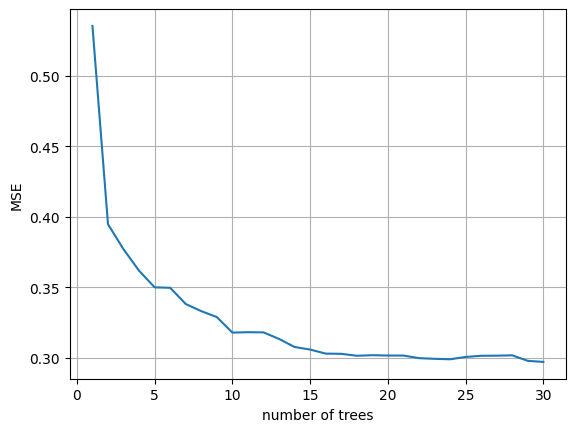

In [ ]:
mse_list = []
for i in range(pred_array.shape[1]):
  pred = np.mean(pred_array[:,:i+1],axis=1)
  mse = mean_squared_error(y_test,pred)
  mse_list.append(mse)
  print(f'Mean_squared_error using prediction average of {i+1} models: {mse:8.6f}')

plt.figure()
plt.plot(np.arange(1,pred_array.shape[1]+1),mse_list)
plt.xlabel('number of trees')
plt.ylabel('MSE')
plt.grid(True)
plt.show()

The algorithm we implemented is the well-known random forest regressor.

In [ ]:
from sklearn.ensemble import RandomForestRegressor
model = RandomForestRegressor(n_estimators = n_tests, n_jobs=-1)
model.fit(X_train,y_train)
pred_train = model.predict(X_train)
pred_test = model.predict(X_test)
print('Mean squared error training = {:7.5f}'.format(mean_squared_error(pred_train,y_train)))
print('Mean squared error test set = {:7.5f}'.format(mean_squared_error(pred_test,y_test)))

Mean squared error training = 0.03934
Mean squared error test set = 0.27826
